# Data audit: raw files and first-look plots

A short audit of the three raw M5 files the project uses, plus the first-look plots of the data.
It reads only `data/raw/` and saves every image to `outputs/figures/data_audit/`, so the images can go straight into the synopsis slides.

| File | What it holds | Used for |
|---|---|---|
| `sales_train_evaluation.csv` | units sold per product, per store, per day (`d_1` … `d_1941`) | the demand series (main variable) |
| `calendar.csv` | the date, week and weekday of each `d_` column, holidays, SNAP days | dates, weekly totals, calendar features |
| `sell_prices.csv` | weekly price per product and store | price features, inventory cost |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

RAW = Path("../data/raw")
OUT = Path("../outputs/figures/data_audit")
OUT.mkdir(parents=True, exist_ok=True)

# Colours chosen to sit on the synopsis slides (cream paper, dark teal ink, brick-red accent)
INK, ACCENT, TEAL, PAPER, ROW, GRID, MUTED = "#17323D", "#C0452B", "#4E8C8C", "#FFFDF8", "#F3EBDF", "#E4DCCF", "#6B7378"
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
})

sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv")
for name, df in [("sales", sales), ("calendar", calendar), ("prices", prices)]:
    print(f"{name:9s} {df.shape[0]:>9,} rows x {df.shape[1]:>5,} columns   empty cells: {int(df.isna().sum().sum()):,}")

sales        30,490 rows x 1,947 columns   empty cells: 0
calendar      1,969 rows x    14 columns   empty cells: 7,542
prices    6,841,121 rows x     4 columns   empty cells: 0


## 1. Data snapshots

One image per file, plus all three stacked in one image for the slide's snapshot box.
The sales file is very wide (1,941 day columns), so only the first and last three days are shown.

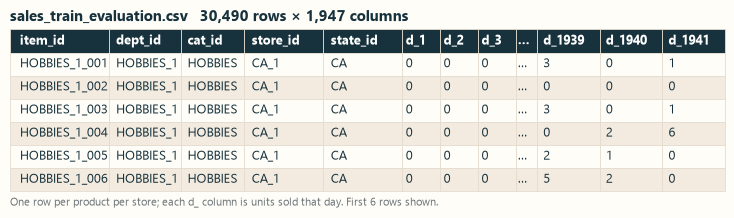

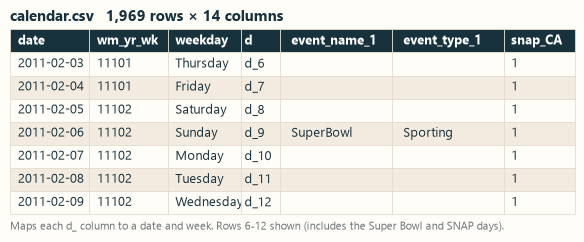

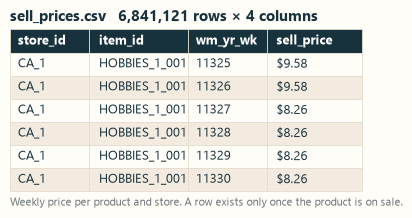

In [2]:
def table_png(df, title, fname, note=None):
    """Render a small DataFrame as a styled table image."""
    df = df.fillna("").astype(str)
    chars = np.array([max(1.25 * len(str(c)), df[c].str.len().max()) for c in df.columns], dtype=float) + 2
    fig, ax = plt.subplots(figsize=(0.085 * chars.sum(), 0.3 * (len(df) + 1)))
    ax.axis("off")
    t = ax.table(cellText=df.values, colLabels=df.columns, bbox=[0, 0, 1, 1], cellLoc="left", colLoc="left",
                 colWidths=list(chars / chars.sum()))
    t.auto_set_font_size(False); t.set_fontsize(9)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor(GRID); cell.set_linewidth(0.6)
        if r == 0:
            cell.set_facecolor(INK); cell.get_text().set_color("white"); cell.get_text().set_fontweight("bold")
        else:
            cell.set_facecolor(PAPER if r % 2 else ROW)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", pad=6)
    if note:
        ax.text(0, -0.04, note, transform=ax.transAxes, fontsize=8, color=MUTED, va="top")
    path = OUT / fname
    fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.12)
    plt.show()
    return path

# Sales: id columns, the first three and the last three days
day_cols = [c for c in sales.columns if c.startswith("d_")]
snap_sales = sales[["item_id", "dept_id", "cat_id", "store_id", "state_id"] + day_cols[:3] + day_cols[-3:]].head(6).copy()
snap_sales.insert(8, "…", "…")
p1 = table_png(snap_sales, f"sales_train_evaluation.csv   {sales.shape[0]:,} rows × {sales.shape[1]:,} columns",
               "snapshot_sales.png", "One row per product per store; each d_ column is units sold that day. First 6 rows shown.")

# Calendar: rows 6-12, which include a holiday and SNAP days
snap_cal = calendar[["date", "wm_yr_wk", "weekday", "d", "event_name_1", "event_type_1", "snap_CA"]].iloc[5:12].copy()
snap_cal["date"] = snap_cal["date"].dt.strftime("%Y-%m-%d")
p2 = table_png(snap_cal, f"calendar.csv   {calendar.shape[0]:,} rows × {calendar.shape[1]} columns", "snapshot_calendar.png",
               "Maps each d_ column to a date and week. Rows 6-12 shown (includes the Super Bowl and SNAP days).")

# Prices: first rows
snap_pr = prices.head(6).copy()
snap_pr["sell_price"] = snap_pr["sell_price"].map("${:.2f}".format)
p3 = table_png(snap_pr, f"sell_prices.csv   {prices.shape[0]:,} rows × {prices.shape[1]} columns", "snapshot_prices.png",
               "Weekly price per product and store. A row exists only once the product is on sale.")

In [3]:
# All three stacked into one image for the slide
imgs = [Image.open(p).convert("RGB") for p in (p1, p2, p3)]
gap, w = 30, max(i.width for i in imgs)
combined = Image.new("RGB", (w, sum(i.height for i in imgs) + gap * 2), PAPER)
y = 0
for im in imgs:
    combined.paste(im, (0, y)); y += im.height + gap
combined.save(OUT / "snapshot_all_files.png")
print("saved", OUT / "snapshot_all_files.png", combined.size)

saved ..\outputs\figures\data_audit\snapshot_all_files.png (1477, 1446)


## 2. First-look plots

All three use California (the main study), with each product's sales summed across the four CA stores, as in the analysis.

In [4]:
ca = sales[sales["state_id"] == "CA"]
item_daily = ca.groupby(["item_id", "cat_id"])[day_cols].sum()      # 3,049 products x 1,941 days
d2date = calendar.set_index("d")["date"]
d2week = calendar.set_index("d")["wm_yr_wk"]
print("CA products:", len(item_daily))

CA products: 3049


### 2a. Line plot: weekly sales of one product, 2011-2016
`FOODS_3_586` is California's second-best-selling product and a steady (AX) seller. The dotted line marks the lasting upward shift the CUSUM detector found in June 2014 (notebook 01).

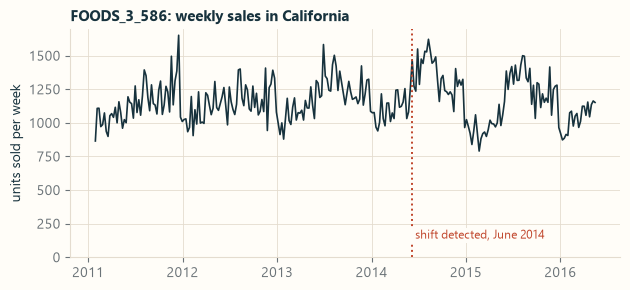

277 full weeks, 2011-01-29 to 2016-05-14


In [5]:
ITEM = "FOODS_3_586"
s = item_daily.xs(ITEM, level="item_id").iloc[0]
wk = pd.DataFrame({"sales": s.values, "date": d2date[s.index].values, "week": d2week[s.index].values})
weekly = wk.groupby("week").agg(sales=("sales", "sum"), start=("date", "min"), days=("date", "size"))
weekly = weekly[weekly["days"] == 7]                                   # full weeks only

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(weekly["start"], weekly["sales"], color=INK, lw=1.2)
brk = pd.Timestamp("2014-06-07")
ax.axvline(brk, color=ACCENT, ls=":", lw=1.4)
ax.text(brk, 120, " shift detected, June 2014", color=ACCENT, fontsize=8.5, va="bottom",
        bbox=dict(facecolor=PAPER, edgecolor="none", pad=1))
ax.set_ylabel("units sold per week")
ax.set_title(f"{ITEM}: weekly sales in California", loc="left", fontsize=11, fontweight="bold")
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(OUT / "plot_line_one_product.png", dpi=200)
plt.show()
print(f"{len(weekly)} full weeks, {weekly['start'].min():%Y-%m-%d} to {weekly['start'].max():%Y-%m-%d}")

### 2b. Missing and zero values: zero-sales days before each product's first sale
The sales file has no empty cells, but many products show long runs of zeros before they were first sold. Those zeros are not real demand, so the analysis trims each series at its first sale.

Empty sales cells: 0
Products with more than 30 leading zero days: 1,565 of 3,049 (51.3%)
{'FOODS': 714, 'HOBBIES': 303, 'HOUSEHOLD': 548}


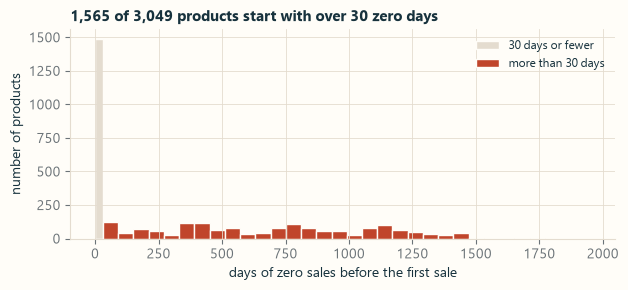

In [6]:
vals = item_daily.values
first_sale = np.where((vals > 0).any(axis=1), (vals > 0).argmax(axis=1), vals.shape[1])
lead = pd.Series(first_sale, index=item_daily.index.get_level_values("item_id"), name="leading_zero_days")
n_long = int((lead > 30).sum())
print(f"Empty sales cells: {int(sales[day_cols].isna().sum().sum())}")
print(f"Products with more than 30 leading zero days: {n_long:,} of {len(lead):,} ({n_long / len(lead):.1%})")
print(lead.groupby(item_daily.index.get_level_values("cat_id")).apply(lambda x: (x > 30).sum()).to_dict())

edges = np.r_[0, 31, np.arange(91, 1942 + 60, 60)]
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(lead[lead <= 30], bins=edges, color=GRID, edgecolor=PAPER, label="30 days or fewer")
ax.hist(lead[lead > 30], bins=edges, color=ACCENT, edgecolor=PAPER, label="more than 30 days")
ax.set_xlabel("days of zero sales before the first sale")
ax.set_ylabel("number of products")
ax.set_title(f"{n_long:,} of {len(lead):,} products start with over 30 zero days", loc="left", fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(OUT / "plot_zero_values.png", dpi=200)
plt.show()

### 2c. Seasonal plot: average sales for each day of the week
Shown as an index (100 = that category's average day) so the three categories, which differ greatly in volume, can be compared on one scale.

cat_id     FOODS  HOBBIES  HOUSEHOLD
weekday                             
Monday      97.4     94.9       96.6
Tuesday     88.5     91.1       86.4
Wednesday   86.3     90.1       83.4
Thursday    86.8     90.1       83.4
Friday      98.0    101.1       95.7
Saturday   119.7    120.5      126.0
Sunday     123.0    112.2      128.2


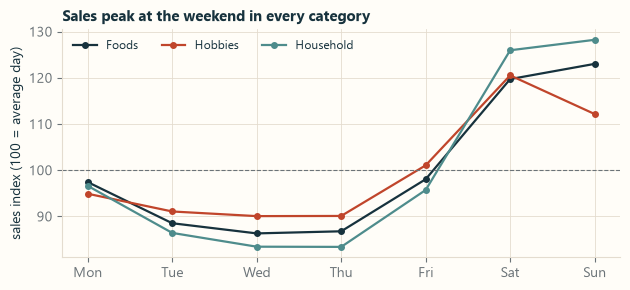

In [7]:
cat_daily = item_daily.groupby(level="cat_id").sum().T                # days x categories
cat_daily["weekday"] = calendar.set_index("d").loc[cat_daily.index, "weekday"].values
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = cat_daily.groupby("weekday").mean().loc[order]
index = 100 * by_day / cat_daily.drop(columns="weekday").mean()
print(index.round(1))

fig, ax = plt.subplots(figsize=(6.4, 3.0))
for cat, colour in zip(["FOODS", "HOBBIES", "HOUSEHOLD"], [INK, ACCENT, TEAL]):
    ax.plot(range(7), index[cat], marker="o", ms=4, lw=1.6, color=colour, label=cat.title())
ax.axhline(100, color=MUTED, lw=0.8, ls="--")
ax.set_xticks(range(7), [d[:3] for d in order])
ax.set_ylabel("sales index (100 = average day)")
ax.set_title("Sales peak at the weekend in every category", loc="left", fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "plot_seasonal_weekday.png", dpi=200)
plt.show()

## Saved images
All in `outputs/figures/data_audit/`:

| File | Slide use |
|---|---|
| `snapshot_all_files.png` | dataset snapshot box (all three files) |
| `snapshot_sales.png`, `snapshot_calendar.png`, `snapshot_prices.png` | one file each |
| `plot_line_one_product.png` | Line plot |
| `plot_zero_values.png` | Missing and zero values |
| `plot_seasonal_weekday.png` | Seasonal plot |